# Acqua e denaro
**Principi e modelli della percezione — Prof.ssa Elena Casiraghi, Università degli Studi di Milano**
Aaliyah Elchico, Sarah Fadli

**Domanda:** i fondi pubblici contro le alluvioni nelle Filippine arrivano nei comuni che si allagano davvero?

Mettiamo insieme due fonti:
1. **Il denaro**: i progetti anti-alluvione del Ministero dei lavori pubblici filippino (DPWH), 2018–2025 (BetterGov Open Data Portal).
2. **L'acqua**: le aree allagate del 6 luglio 2025 rilevate dal radar del satellite Sentinel-1A (PhilSA).

Per ogni comune calcoliamo quanta acqua e quanti soldi ha ricevuto, poi raggruppiamo i comuni simili con **K-Means** e controlliamo i gruppi con **Mean-Shift**.

## 0. Preparazione
Su Colab il notebook legge i file dalla cartella Drive `progetto_principi_percezione`.

In [1]:
import os, json, warnings
warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    drive.mount("/content/drive")
    !pip -q install geopandas
except ImportError:
    pass

DATA = os.environ.get("DATA_DIR", "/content/drive/MyDrive/progetto_principi_percezione/")

import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy.stats import skew, spearmanr, kruskal
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, MeanShift, estimate_bandwidth
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

# Palette della presentazione: azzurro = acqua, marrone = denaro
ACQUA, DENARO, CREMA = "#6F97C2", "#34211B", "#F6F1EA"
COL = {0: "#34211B", 1: "#B07A52", 2: "#CDBDAA", 3: "#6F97C2"}
plt.rcParams.update({"figure.facecolor": CREMA, "axes.facecolor": CREMA, "axes.spines.top": False, "axes.spines.right": False})
UTM = "EPSG:32651"   # proiezione in metri per misurare le aree

## 1. I dati

### 1.1 Il denaro: i progetti DPWH
Ogni riga è un contratto. Le variabili che usiamo:

| Variabile | Tipo | Significato |
|---|---|---|
| `ContractID` | categorica (identificativo) | codice del contratto |
| `Longitude`, `Latitude` | numerica continua | posizione del progetto |
| `ContractCost` | numerica continua | valore del contratto in pesos |
| `TypeofWork` | categorica nominale | tipo di opera (argine, muro di sponda, drenaggio…) |
| `InfraYear` | numerica discreta | anno |
| `Province`, `Municipality` | categorica nominale | dove si trova |

In [2]:
feats = json.load(open(DATA + "flood_control.json"))["features"]
P = pd.DataFrame([f["attributes"] for f in feats])
print("righe:", len(P))
P[["ContractID", "Longitude", "Latitude", "ContractCost", "TypeofWork", "InfraYear", "Province", "Municipality"]].head()

righe: 9855


,ContractID,Longitude,Latitude,ContractCost,TypeofWork,InfraYear,Province,Municipality
0,24EG0058,118.892450,9.996530,1.796157e+07,Construction of Flood Mitigation Structure,2024,PALAWAN,PUERTO PRINCESA CITY (CAPITAL) (PALAWAN)
1,24EG0057,118.892510,9.997610,1.736999e+07,Construction of Flood Mitigation Structure,2024,PALAWAN,PUERTO PRINCESA CITY (CAPITAL) (PALAWAN)
2,24EG0017,118.893230,9.996710,1.680261e+07,Construction of Flood Mitigation Structure,2024,PALAWAN,PUERTO PRINCESA CITY (CAPITAL) (PALAWAN)
3,23EG0016,118.899702,10.002658,4.899590e+06,Construction of Drainage Structure,2023,PALAWAN,PUERTO PRINCESA CITY (CAPITAL) (PALAWAN)
4,24E00127,118.990177,9.999043,1.543954e+08,Construction of Flood Mitigation Structure,2024,PALAWAN,PUERTO PRINCESA CITY (CAPITAL) (PALAWAN)


In [3]:
P["TypeofWork"].value_counts().head(8)

TypeofWork
Construction of Flood Mitigation Structure                  6352
Construction of Revetment                                    747
Construction of Slope Protection Structure                   739
Construction of Drainage Structure                           679
Rehabilitation / Major Repair of Flood Control Structure     648
Construction of Dike                                         225
Rehabilitation / Major Repair of Drainage Structure          215
Construction of Flood Mitigation Facility                    170
Name: count, dtype: int64

Ci sono contratti ripetuti: li togliamo. Convertiamo coordinate e costi in numeri.

In [4]:
P = P.drop_duplicates("ContractID")
for c in ["Longitude", "Latitude", "ContractCost"]:
    P[c] = pd.to_numeric(P[c], errors="coerce")
P["ContractCost"] = P["ContractCost"].fillna(0)
P = P.dropna(subset=["Longitude", "Latitude"])
print("contratti unici con coordinate:", len(P), "· valore totale:", round(P.ContractCost.sum() / 1e9, 1), "miliardi di pesos")

contratti unici con coordinate: 9698 · valore totale: 541.2 miliardi di pesos


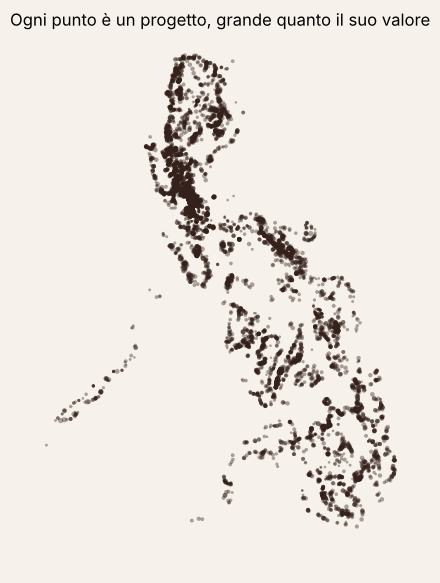

In [5]:
fig, ax = plt.subplots(figsize=(5, 7))
ax.scatter(P.Longitude, P.Latitude, s=1.5 + np.sqrt(P.ContractCost / 1e6) * 0.9, c=DENARO, alpha=0.4, lw=0)
ax.set_xlim(116.8, 126.8); ax.set_ylim(4.5, 19.2); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Ogni punto è un progetto, grande quanto il suo valore");

### 1.2 L'acqua: le aree allagate del 6 luglio 2025
Lo shapefile PhilSA contiene poligoni di acqua rilevata dal radar (variabile geometrica).

In [6]:
fl = gpd.read_file(DATA + "20250706_Flood_S1A.shp")[["geometry"]]
fl["geometry"] = fl.geometry.make_valid()
print("poligoni allagati:", len(fl))

poligoni allagati: 61774


### 1.3 I comuni
I confini amministrativi (livello 3 = comuni) servono per unire le due fonti.

In [7]:
adm3 = gpd.read_file(DATA + "phl_admin3.shp", columns=["adm3_name", "adm3_pcode", "adm2_name", "area_sqkm"])
adm3["geometry"] = adm3.geometry.simplify(0.0005)
print("comuni:", len(adm3))

comuni: 1642


## 2. Dal progetto al comune

**Filtro di copertura.** Il satellite osserva solo una parte del Paese. Un comune fuori dall'area osservata non è "non allagato": semplicemente non lo sappiamo. Il file con l'area osservata non era disponibile, quindi la **ricostruiamo come involucro convesso delle aree allagate** e teniamo solo i comuni che ci cadono dentro.

In [8]:
hull = fl.union_all().convex_hull
adm3["in_cov"] = adm3.geometry.representative_point().within(hull)
print("comuni dentro l'area osservata:", adm3.in_cov.sum())

comuni dentro l'area osservata: 577


**Acqua per comune**: ritagliamo i poligoni allagati sui confini dei comuni e sommiamo le aree in km². *(È il passaggio più lento, qualche minuto.)*

In [9]:
a3 = adm3[adm3.in_cov].to_crs(UTM)
inter = gpd.overlay(fl.to_crs(UTM), a3[["adm3_pcode", "geometry"]], how="intersection", keep_geom_type=True)
flood_km2 = (inter.area / 1e6).groupby(inter.adm3_pcode).sum()

**Denaro per comune**: ogni progetto va al comune in cui cadono le sue coordinate (unione spaziale). È più affidabile che confrontare i nomi, scritti in modi diversi.

In [10]:
pg = gpd.GeoDataFrame(P, geometry=gpd.points_from_xy(P.Longitude, P.Latitude), crs="EPSG:4326")
pj = gpd.sjoin(pg, adm3[["adm3_pcode", "geometry"]], predicate="within")
agg = pj.groupby("adm3_pcode").agg(n_progetti=("ContractID", "count"), budget=("ContractCost", "sum"))
print("progetti collocati in un comune:", len(pj))

progetti collocati in un comune: 9487


**La tabella finale**: una riga per comune, cinque misure.

In [11]:
T = adm3[adm3.in_cov].drop(columns="geometry").set_index("adm3_pcode")
T["area_km2"] = a3.set_index("adm3_pcode").area / 1e6
T["flood_km2"] = flood_km2.reindex(T.index).fillna(0)
T = T.join(agg).fillna({"n_progetti": 0, "budget": 0})
T["quota_allagata"] = T.flood_km2 / T.area_km2
T["budget_per_km2"] = T.budget / T.area_km2
print(len(T), "comuni in", T.adm2_name.nunique(), "province")
T[["adm3_name", "adm2_name", "flood_km2", "quota_allagata", "budget", "n_progetti", "budget_per_km2"]].describe().round(2)

577 comuni in 35 province


,flood_km2,quota_allagata,budget,n_progetti,budget_per_km2
count,577.00,577.00,5.770000e+02,577.00,5.770000e+02
mean,6.50,0.05,5.090658e+08,9.32,9.146754e+06
std,12.11,0.09,9.616190e+08,15.81,3.441611e+07
min,0.00,0.00,0.000000e+00,0.00,0.000000e+00
25%,0.16,0.00,4.211510e+07,1.00,2.594674e+05
50%,1.39,0.01,1.929984e+08,4.00,1.533697e+06
75%,7.06,0.05,5.948511e+08,11.00,5.738771e+06
max,107.91,0.58,1.419370e+10,211.00,5.864568e+08


| Misura | Tipo | Significato |
|---|---|---|
| `flood_km2` | numerica continua | km² allagati il 6 luglio 2025 |
| `quota_allagata` | numerica continua (0–1) | parte del territorio allagata |
| `budget` | numerica continua | somma dei contratti, pesos |
| `n_progetti` | numerica discreta | numero di contratti |
| `budget_per_km2` | numerica continua | budget diviso la superficie |

### 2.1 Acqua contro denaro
Il clustering non ha una variabile *target*, ma la nostra domanda mette a confronto acqua e denaro: guardiamoli insieme.

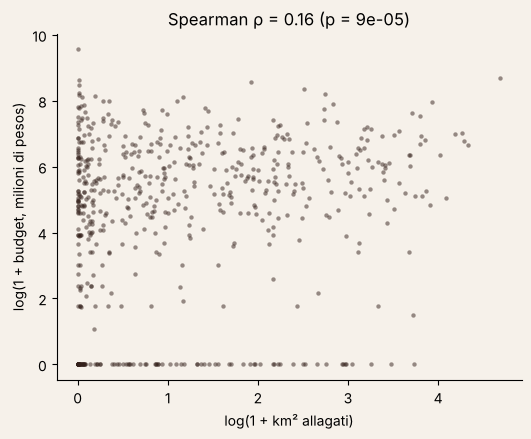

In [12]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(np.log1p(T.flood_km2), np.log1p(T.budget / 1e6), s=10, c=DENARO, alpha=0.5, lw=0)
ax.set_xlabel("log(1 + km² allagati)"); ax.set_ylabel("log(1 + budget, milioni di pesos)")
r = spearmanr(T.flood_km2, T.budget)
ax.set_title(f"Spearman ρ = {r.statistic:.2f} (p = {r.pvalue:.0e})");

Il legame è **positivo ma debole**: più acqua va con un po' più di fondi, ma tanti comuni allagati ricevono poco o niente.

## 3. Normalizzazione
Due problemi:
1. **Code lunghe**: pochi comuni con valori enormi schiaccerebbero tutti gli altri. Usiamo `log(1 + x)` per le misure in km² e in pesos, e la radice quadrata per la quota allagata.
2. **Scale diverse**: km² e pesos non sono confrontabili. Con la **standardizzazione** ogni misura ha media 0 e deviazione standard 1.

In [13]:
X = pd.DataFrame({
    "km² allagati":   np.log1p(T.flood_km2),
    "Quota allagata": np.sqrt(T.quota_allagata),
    "Budget totale":  np.log1p(T.budget / 1e6),
    "N. progetti":    np.log1p(T.n_progetti),
    "Budget per km²": np.log1p(T.budget_per_km2 / 1e6),
}, index=T.index)
prima = T[["flood_km2", "quota_allagata", "budget", "n_progetti", "budget_per_km2"]].apply(skew).round(2).values
pd.DataFrame({"asimmetria prima": prima, "asimmetria dopo": X.apply(skew).round(2).values}, index=X.columns)

,asimmetria prima,asimmetria dopo
km² allagati,3.34,0.77
Quota allagata,2.94,1.37
Budget totale,6.67,-0.84
N. progetti,5.93,0.17
Budget per km²,10.87,1.17


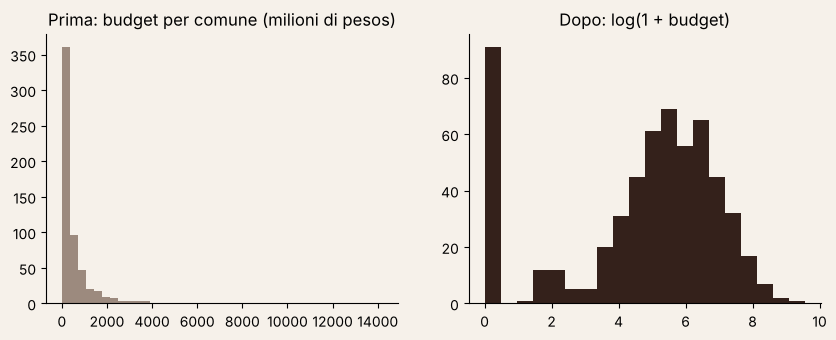

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
axs[0].hist(T.budget / 1e6, bins=40, color="#9C8A7E"); axs[0].set_title("Prima: budget per comune (milioni di pesos)")
axs[1].hist(X["Budget totale"], bins=20, color=DENARO); axs[1].set_title("Dopo: log(1 + budget)")
Z = StandardScaler().fit_transform(X)

## 4. K-Means
Il legame con il corso: per la **Gestalt** l'occhio raggruppa gli oggetti vicini (*vicinanza*) e simili (*somiglianza*). K-Means fa lo stesso con le distanze tra comuni.

**Quanti gruppi?** Proviamo K da 2 a 8 e guardiamo il **gomito** (inerzia) e la **silhouette**.

,K,inerzia,silhouette
0,2,1840.859,0.320
1,3,1252.205,0.351
2,4,921.868,0.363
3,5,789.492,0.362
4,6,681.295,0.338
5,7,590.955,0.332
6,8,522.982,0.334


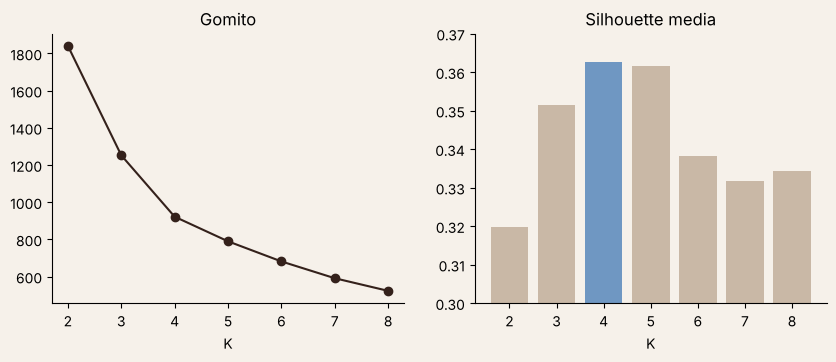

In [15]:
res = []
for k in range(2, 9):
    km = KMeans(k, n_init=20, random_state=42).fit(Z)
    res.append((k, km.inertia_, silhouette_score(Z, km.labels_)))
res = pd.DataFrame(res, columns=["K", "inerzia", "silhouette"])
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
axs[0].plot(res.K, res.inerzia, "o-", color=DENARO); axs[0].set_title("Gomito"); axs[0].set_xlabel("K")
axs[1].bar(res.K, res.silhouette, color=[ACQUA if k == 4 else "#C9B8A6" for k in res.K]); axs[1].set_ylim(0.3, 0.37); axs[1].set_title("Silhouette media"); axs[1].set_xlabel("K")
res.round(3)

Dopo K = 4 il gomito si appiattisce e la silhouette è massima (0,36): scegliamo **K = 4**. Una silhouette moderata significa che i gruppi esistono ma hanno confini sfumati.

In [16]:
K = 4
km = KMeans(K, n_init=50, random_state=42).fit(Z)
T["cluster"] = km.labels_
T.cluster.value_counts().sort_index()

cluster
0    110
1    118
2    217
3    132
Name: count, dtype: int64

## 5. Chi c'è in ogni gruppo
Valori **mediani** nella scala originale.

In [17]:
prof = T.groupby("cluster").agg(comuni=("adm3_name", "count"),
                                 km2_allagati=("flood_km2", "median"),
                                 quota_allagata=("quota_allagata", "median"),
                                 budget_mln=("budget", lambda s: s.median() / 1e6),
                                 progetti=("n_progetti", "median"))
prof.round(3)

,comuni,km2_allagati,quota_allagata,budget_mln,progetti
cluster,,,,,
0,110,0.345,0.004,1019.827,19.0
1,118,0.520,0.006,0.000,0.0
2,217,0.883,0.006,161.351,3.0
3,132,17.637,0.139,392.782,7.0


Leggendo la tabella diamo un nome ai gruppi. *(Con `random_state=42` i numeri dei gruppi sono quelli sotto; se cambiano, aggiornare i nomi.)*

,acqua,denaro
gruppo,,
Acqua senza fondi,9.1,0.1
Molta acqua,76.9,26.3
"Molti fondi, poca acqua",3.5,57.5
"Poca acqua, pochi fondi",10.5,16.1


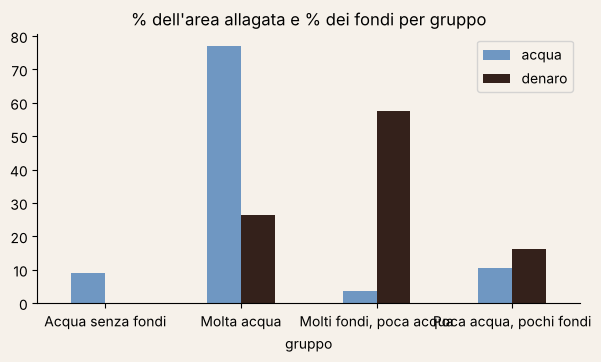

In [18]:
NOMI = {0: "Molti fondi, poca acqua", 1: "Acqua senza fondi", 2: "Poca acqua, pochi fondi", 3: "Molta acqua"}
T["gruppo"] = T.cluster.map(NOMI)
quote = T.groupby("gruppo").agg(acqua=("flood_km2", "sum"), denaro=("budget", "sum"))
quote = (100 * quote / quote.sum()).round(1)
quote.plot.bar(color=[ACQUA, DENARO], figsize=(7, 3.5), rot=0, title="% dell'area allagata e % dei fondi per gruppo")
quote

Il gruppo **molta acqua** ha il 77% dell'area allagata ma il 26% dei fondi. Il gruppo **molti fondi** ha il 58% dei soldi e il 3,5% dell'acqua.

In [19]:
T[T.gruppo == "Acqua senza fondi"].sort_values("flood_km2", ascending=False)[["adm3_name", "adm2_name", "flood_km2", "n_progetti"]].head(8)

,adm3_name,adm2_name,flood_km2,n_progetti
adm3_pcode,,,,
PH0201503,Allacapan,Cagayan,31.537317,0.0
PH0201528,Tuao,Cagayan,24.930069,0.0
PH0205703,Diffun,Quirino,20.086518,0.0
PH0203118,Delfin Albano (Magsaysay),Isabela,18.408890,0.0
PH1408103,Flora,Apayao,17.870570,0.0
PH0304932,Zaragoza,Nueva Ecija,14.758340,0.0
PH1705210,Pola,Oriental Mindoro,13.350226,1.0
PH0304913,Laur,Nueva Ecija,13.285391,0.0


## 6. Controprova con Mean-Shift
Mean-Shift non chiede K: sposta ogni punto verso la zona più densa e trova da solo i gruppi. La larghezza di banda viene stimata dai dati (quantile 0,1).
Misuriamo l'accordo con K-Means con l'**Adjusted Rand Index** (1 = identici, 0 = a caso).

In [20]:
bw = estimate_bandwidth(Z, quantile=0.1, random_state=42)
ms = MeanShift(bandwidth=bw, bin_seeding=True).fit(Z)
T["ms"] = ms.labels_
print("gruppi trovati da Mean-Shift:", T.ms.nunique(), "· ARI:", round(adjusted_rand_score(T.cluster, T.ms), 2))
pd.crosstab(T.gruppo, T.ms)

gruppi trovati da Mean-Shift: 5 · ARI: 0.59


ms,0,1,2,3,4
gruppo,,,,,
Acqua senza fondi,0,107,1,10,0
Molta acqua,0,0,121,11,0
"Molti fondi, poca acqua",50,0,30,0,30
"Poca acqua, pochi fondi",194,0,23,0,0


Per vedere i gruppi in due dimensioni usiamo la **PCA**. Le ellissi attorno ai gruppi usano il principio di **recinzione**.

varianza spiegata: [0.54 0.37]


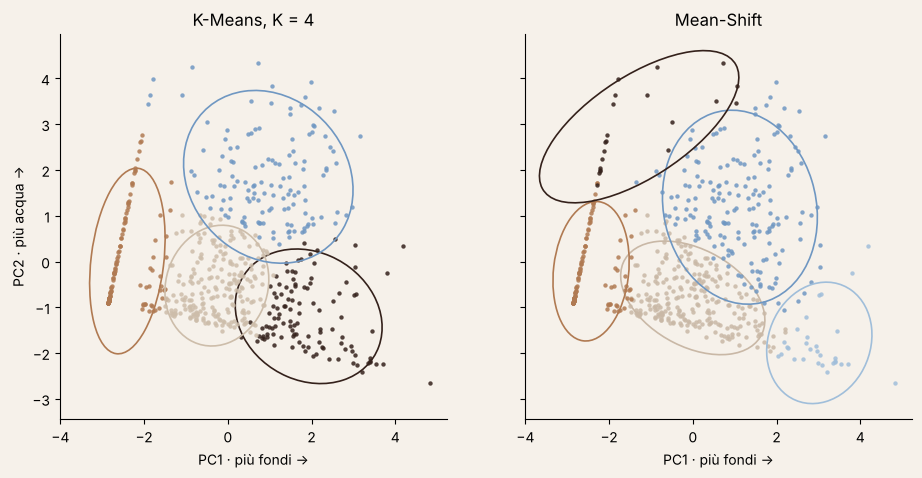

In [21]:
pca = PCA(2).fit(Z); P2 = pca.transform(Z); T["pc1"], T["pc2"] = P2[:, 0], P2[:, 1]
print("varianza spiegata:", pca.explained_variance_ratio_.round(2))
MSC = ["#C9B8A6", "#B07A52", "#6F97C2", "#34211B", "#A0BEDA"]
fig, axs = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, lab, cols, ttl in [(axs[0], "cluster", COL, "K-Means, K = 4"), (axs[1], "ms", dict(enumerate(MSC)), "Mean-Shift")]:
    for c in sorted(T[lab].unique()):
        s = T[T[lab] == c]
        ax.scatter(s.pc1, s.pc2, s=10, color=cols[c % len(cols)], alpha=0.85, lw=0)
        if len(s) > 5:
            v, w = np.linalg.eigh(np.cov(s.pc1, s.pc2)); ang = np.degrees(np.arctan2(w[1, 1], w[0, 1]))
            ax.add_patch(Ellipse((s.pc1.mean(), s.pc2.mean()), 4 * np.sqrt(v[1]), 4 * np.sqrt(v[0]), angle=ang, fill=False, ec=cols[c % len(cols)], lw=1.2))
    ax.set_title(ttl); ax.set_xlabel("PC1 · più fondi →")
axs[0].set_ylabel("PC2 · più acqua →");

## 7. La mappa
Latitudine e longitudine **non** entrano nell'algoritmo: se i gruppi formano macchie compatte sulla mappa, hanno colto qualcosa di reale del territorio.

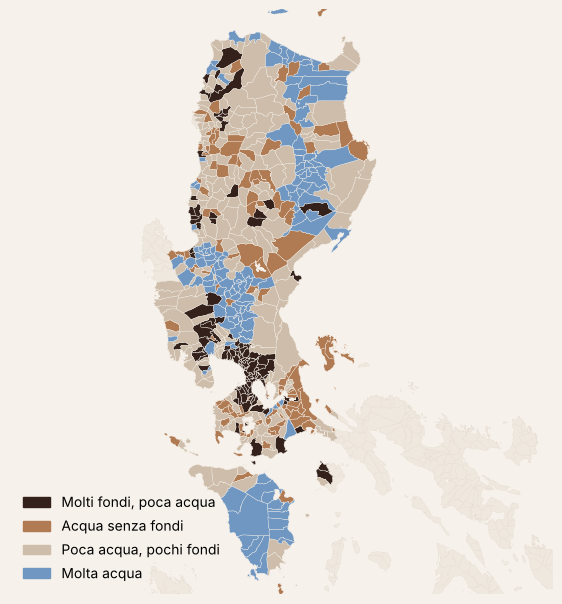

In [22]:
m = adm3.merge(T[["cluster"]], left_on="adm3_pcode", right_index=True, how="left")
fig, ax = plt.subplots(figsize=(7, 8))
m[m.cluster.isna()].plot(ax=ax, color="#EFE8DF", edgecolor="#E6DDD2", lw=0.2)
for c in range(K):
    m[m.cluster == c].plot(ax=ax, color=COL[c], edgecolor=CREMA, lw=0.25, label=NOMI[c])
ax.set_xlim(118.2, 124.6); ax.set_ylim(12.0, 18.9); ax.set_aspect("equal"); ax.axis("off")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COL[c], label=NOMI[c]) for c in range(K)], loc="lower left", frameon=False);

## 8. Quali misure contano di più
- **Kruskal-Wallis**: per ogni misura, i gruppi sono diversi? (test non parametrico, adatto a dati non normali)
- **Random Forest + permutation importance**: un modello impara a riconoscere il gruppo; mescolando una misura alla volta vediamo quanto peggiora.

,Kruskal H,p-value,permutation importance
Budget totale,405.0565,0.0,0.3019
Quota allagata,268.5201,0.0,0.1727
Budget per km²,423.2232,0.0,0.1631
km² allagati,276.1070,0.0,0.1321
N. progetti,395.0015,0.0,0.0258


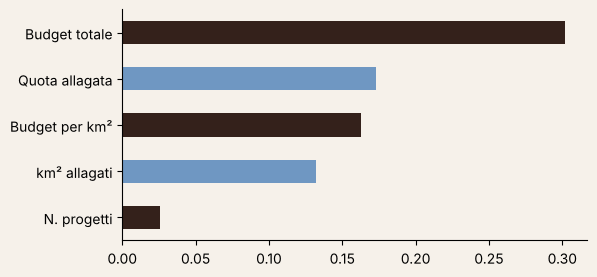

In [23]:
H = {c: kruskal(*[X[c][T.cluster == k] for k in range(K)]) for c in X.columns}
rf = RandomForestClassifier(300, random_state=42).fit(Z, T.cluster)
pi = permutation_importance(rf, Z, T.cluster, n_repeats=20, random_state=42)
imp = pd.DataFrame({"Kruskal H": {c: h.statistic for c, h in H.items()}, "p-value": {c: h.pvalue for c, h in H.items()},
                    "permutation importance": pd.Series(pi.importances_mean, index=X.columns)}).sort_values("permutation importance")
imp["permutation importance"].plot.barh(color=[DENARO if "udget" in c or "progetti" in c else ACQUA for c in imp.index], figsize=(6, 3))
imp.sort_values("permutation importance", ascending=False).round(4)

## 9. Conclusioni
- **Il denaro segue l'acqua solo in parte.** I comuni più allagati hanno il 77% dell'acqua ma il 26% dei fondi; i comuni con più fondi si allagano poco.
- Esistono **comuni molto allagati senza nessun progetto** (es. Allacapan e Tuao in Cagayan).
- K-Means e Mean-Shift concordano sui gruppi principali (ARI ≈ 0,6).
- A separare i gruppi sono prima di tutto il **budget**, poi la **quota allagata**.

**Limiti**
- Un solo evento alluvionale: un comune può essere a rischio anche se il 6 luglio non si è allagato.
- L'area osservata dal satellite è ricostruita da noi.
- "Zero progetti" può significare progetti senza coordinate.
- Il budget dice quanto si spende, non se le opere funzionano.

In [24]:
T.to_csv("comuni_cluster.csv")